In [1]:
# Install required packages
!pip install vit_keras tensorflow-addons

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 611.8/611.8 kB 10.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.0 MB/s eta 0:00:00
  Attempting uninstall: typeguard
    Found existing installation: typeguard 4.4.4
    Uninstalling typeguard-4.4.4:
      Successfully uninstalled typeguard-4.4.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.16.1 requires typeguard<5,>=3, but you have typeguard 2.13.3 which is incompatible.
inflect 7.5.0 requires typeguard>=4.0.1, but you have typeguard 2.13.3 which is incompatible.


In [2]:


# Import libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report
from vit_keras import vit


2025-08-26 16:47:54.795718: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756226875.038196      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756226875.111526      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:

# Set dataset path
base_dir = '/kaggle/input/flood-dataset/data'  # Update with your dataset path
IMG_SIZE = 224
BATCH_SIZE = 16  # Adjusted for GPU memory

# Image preprocessing
train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 321 images belonging to 2 classes.
Found 81 images belonging to 2 classes.
Found 71 images belonging to 2 classes.


In [6]:
# Load pre-trained Vision Transformer (ViT-B/16)
base_model = vit.vit_b16(
    image_size=IMG_SIZE,
    pretrained=True,
    include_top=False,
    pretrained_top=False
)

# Freeze the base model layers
base_model.trainable = False

# Add custom classification layers
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs)
x = Dense(1024, activation='relu')(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)  # Assuming 2 classes: Flood, Non-Flood

# Create the new model
model = Model(inputs=inputs, outputs=predictions)


# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)


Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 192s 8s/step - accuracy: 0.7905 - loss: 0.4037 - val_accuracy: 0.9383 - val_loss: 0.1546
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 166s 8s/step - accuracy: 0.9769 - loss: 0.0612 - val_accuracy: 0.9383 - val_loss: 0.1325
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 174s 8s/step - accuracy: 0.9985 - loss: 0.0293 - val_accuracy: 0.9383 - val_loss: 0.1207
Epoch 4/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 162s 8s/step - accuracy: 0.9902 - loss: 0.0331 - val_accuracy: 0.9506 - val_loss: 0.1103
Epoch 5/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 202s 8s/step - accuracy: 1.0000 - loss: 0.0230 - val_accuracy: 0.9630 - val_loss: 0.0948
Epoch 6/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 174s 8s/step - accuracy: 0.9963 - loss: 0.0102 - val_accuracy: 0.9506 - val_loss: 0.0918
Epoch 7/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 163s 8s/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 0.9753 - val_loss: 0.0876
Epoch 8/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 164s 8s/step - accuracy: 1.0000 - loss: 0.0117 - val_accuracy: 0.9753 - v

In [1]:
# Evaluate the model
loss, accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {accuracy:.2f}")


NameError: name 'model' is not defined

In [ ]:
# Save the model
model.save('/kaggle/working/pre_trained_vit_b16_model.keras')
print("Model saved successfully to /kaggle/working/")

5/5 ━━━━━━━━━━━━━━━━━━━━ 32s 6s/step


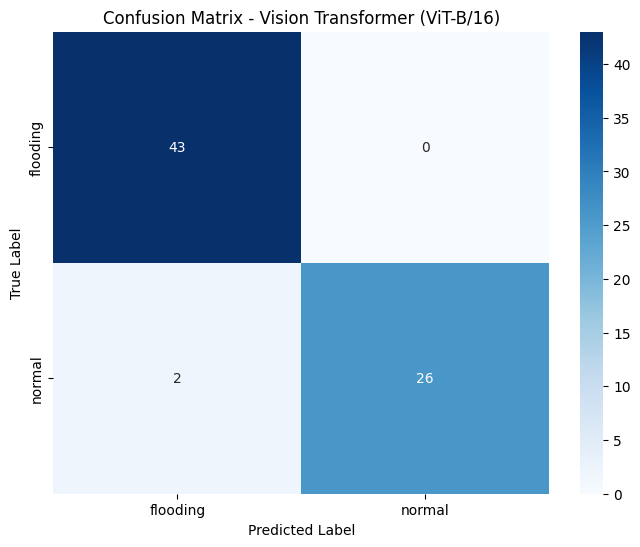

In [8]:

# Generate and plot confusion matrix
predictions = model.predict(test_gen)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Vision Transformer (ViT-B/16)')
plt.savefig('/kaggle/working/confusion_matrix.png')  # Save the plot
plt.show()


In [9]:
# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Classification Report:
              precision    recall  f1-score   support

    flooding       0.96      1.00      0.98        43
      normal       1.00      0.93      0.96        28

    accuracy                           0.97        71
   macro avg       0.98      0.96      0.97        71
weighted avg       0.97      0.97      0.97        71

